In [1]:
import numpy as np
import pandas as pd

# Фиксация seed (обязательно для задания)
np.random.seed(42)

print("Ура! Мой первый ноутбук работает!")

Ура! Мой первый ноутбук работает!


# Data Ingestion & Warm-up Filtering

В этом блоке мы загружаем данные опроса, удаляем "холодные" прогоны (warm-up) и считаем статистику.

In [2]:
import pandas as pd
import json
import os

# Создаем папку data/raw, если ее нет
os.makedirs('../data/raw', exist_ok=True)
file_path = '../data/raw/test_run.jsonl'

# 1. Генерируем тестовые данные и сохраняем их в файл test_run.jsonl
raw_data = [
    {"participant_id": "P1", "agent": "Human", "response": "phishing", "true_label": "phishing", "confidence": 2, "phase": "warmup"},
    {"participant_id": "P2", "agent": "Human", "response": "legitimate", "true_label": "phishing", "confidence": 3, "phase": "warmup"},
    {"participant_id": "P3", "agent": "Human", "response": "phishing", "true_label": "phishing", "confidence": 4, "phase": "benchmark"},
    {"participant_id": "P4", "agent": "Human", "response": "legitimate", "true_label": "phishing", "confidence": 5, "phase": "benchmark"},
    {"participant_id": "P5", "agent": "AI", "response": "phishing", "true_label": "phishing", "confidence": 5, "phase": "benchmark"},
    {"participant_id": "P6", "agent": "AI", "response": "phishing", "true_label": "phishing", "confidence": 4, "phase": "benchmark"},
]

with open(file_path, 'w', encoding='utf-8') as f:
    for record in raw_data:
        f.write(json.dumps(record) + '\n')

print("Файл test_run.jsonl успешно создан на компьютере!")

# 2. Читаем этот файл (вот твой кусок кода из цитаты)
if os.path.exists(file_path):
    df = pd.read_json(file_path, lines=True)
    print("Файл успешно загружен через Pandas!")
else:
    print("ОШИБКА: Файл не найден!")

# 3. Фильтруем warm-up
df_clean = df[df['phase'] == 'benchmark'].copy()
print(f"\nОчищено от warm-up. Осталось записей: {len(df_clean)}")
display(df_clean)


Файл test_run.jsonl успешно создан на компьютере!
Файл успешно загружен через Pandas!

Очищено от warm-up. Осталось записей: 4


,participant_id,agent,response,true_label,confidence,phase
2,P3,Human,phishing,phishing,4,benchmark
3,P4,Human,legitimate,phishing,5,benchmark
4,P5,AI,phishing,phishing,5,benchmark
5,P6,AI,phishing,phishing,4,benchmark


In [3]:
# Считаем статистику
metrics = df_clean.groupby('agent').agg(
    Mean_Confidence=('confidence', 'mean'),
    p95_Confidence=('confidence', lambda x: np.percentile(x, 95)),
    p99_Confidence=('confidence', lambda x: np.percentile(x, 99))
)

print("Метрики посчитаны:")
display(metrics)

Метрики посчитаны:


,Mean_Confidence,p95_Confidence,p99_Confidence
agent,,,
AI,4.5,4.95,4.99
Human,4.5,4.95,4.99


/var/folders/y6/tcjjw1px0wj5d1gtcgd6342c0000gn/T/ipykernel_22524/1418099689.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_clean, x='agent', y='confidence', palette='colorblind', capsize=.1)


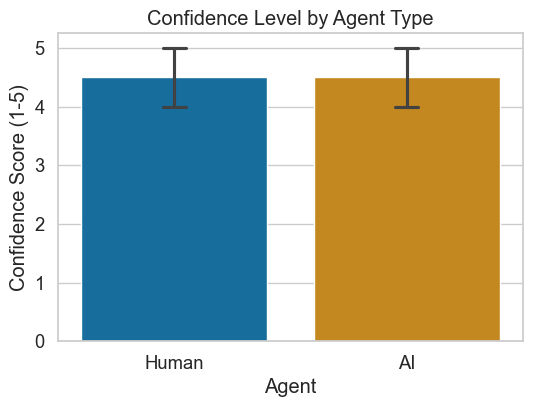

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Настраиваем стиль для графиков (как требуют в ss8)
sns.set_theme(style="whitegrid", font_scale=1.2)

plt.figure(figsize=(6, 4))
# Строим столбчатую диаграмму
sns.barplot(data=df_clean, x='agent', y='confidence', palette='colorblind', capsize=.1)

# Подписываем оси (Правило 1)
plt.title('Confidence Level by Agent Type')
plt.ylabel('Confidence Score (1-5)')
plt.xlabel('Agent')

# Показываем график в ноутбуке
plt.show()